# 01 — EDA & Quality Assurance (Role 2 · Awa)
**Proyek AVM Ames, Iowa (2006–2010) · Kelompok 4 · SI-5203**

**Aturan yang dipatuhi:** (1) data dibagi **80/20 dengan `random_state=42` di awal**, semua keputusan memakai **data latih saja**;
(2) tidak ada `class`/fungsi kustom yang dipakai ulang di luar notebook; (3) outlier **hanya ditandai**, penghapusan dilakukan Role 4 pada `X_train`/`y_train`;
(4) semua angka berasal dari output sel di bawah.

**Output:** `reports/feature_candidates.csv`, `reports/na_mapping.csv`, `reports/outliers_flagged.csv`, `reports/figures/*.png` (300 DPI).

## 0. Setup, pemuatan data, dan split

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, REPORTS, FIGS = ROOT/"data/raw/train.csv", ROOT/"reports", ROOT/"reports/figures"
FIGS.mkdir(parents=True, exist_ok=True)
RANDOM_STATE, TEST_SIZE, REF_YEAR = 42, 0.2, 2010

# PENTING: file ini memakai teks "NA" untuk "fasilitas tidak ada" DAN teks "None" sebagai kategori sah (mis. MasVnrType).
# Default pandas menganggap "None" sebagai NaN -> harus dimatikan.
df_default = pd.read_csv(RAW)
df = pd.read_csv(RAW, keep_default_na=False, na_values=["NA"])
assert df.shape == (1460, 81), df.shape
print("Bentuk data:", df.shape)
print("Total NaN  | default pandas:", int(df_default.isna().sum().sum()), "| penanganan benar (hanya 'NA'):", int(df.isna().sum().sum()))
diff = (df_default.isna().sum() - df.isna().sum())
print("Kolom yang 'bertambah NaN' akibat default pandas:", diff[diff != 0].to_dict())

Bentuk data: (1460, 81)
Total NaN  | default pandas: 7829 | penanganan benar (hanya 'NA'): 6965
Kolom yang 'bertambah NaN' akibat default pandas: {'MasVnrType': 864}


> **Temuan QA #1 (untuk Role 3, 4, 5):** membaca `train.csv` dengan `pd.read_csv()` default mengubah kategori sah `"None"` menjadi NaN
> (kolom `MasVnrType`). Semua kode yang memuat data mentah harus memakai `keep_default_na=False, na_values=["NA"]`.

In [2]:
X = df.drop(columns="SalePrice")
y = df["SalePrice"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print("Latih:", X_train.shape, "| Uji:", X_test.shape)
# Mulai di sini HANYA data latih yang dipakai. X_test/y_test tidak disentuh lagi.
del X_test, y_test
train = X_train.assign(SalePrice=y_train)
ylog = np.log1p(y_train)

Latih: (1168, 80) | Uji: (292, 80)


## 1. Distribusi `SalePrice` vs `np.log1p(SalePrice)`

In [3]:
rows = []
for nama, s in [("SalePrice", y_train), ("log1p(SalePrice)", ylog)]:
    rows.append({"skala": nama, "mean": s.mean(), "median": s.median(), "std": s.std(),
                 "skewness": s.skew(), "excess_kurtosis": s.kurt(),
                 "shapiro_p": stats.shapiro(s).pvalue})
skew_tbl = pd.DataFrame(rows).set_index("skala")
display(skew_tbl.round(4))
skew_before, skew_after = skew_tbl.loc["SalePrice","skewness"], skew_tbl.loc["log1p(SalePrice)","skewness"]
print(f"Skewness: {skew_before:.3f} (asli)  ->  {skew_after:.3f} (log1p)   | |skew| turun {abs(skew_before)-abs(skew_after):.3f}")

,mean,median,std,skewness,excess_kurtosis,shapiro_p
skala,,,,,,
SalePrice,181441.5420,165000.0000,77263.5839,1.7431,5.4753,0.0
log1p(SalePrice),12.0307,12.0137,0.3906,0.1249,0.7002,0.0


Skewness: 1.743 (asli)  ->  0.125 (log1p)   | |skew| turun 1.618


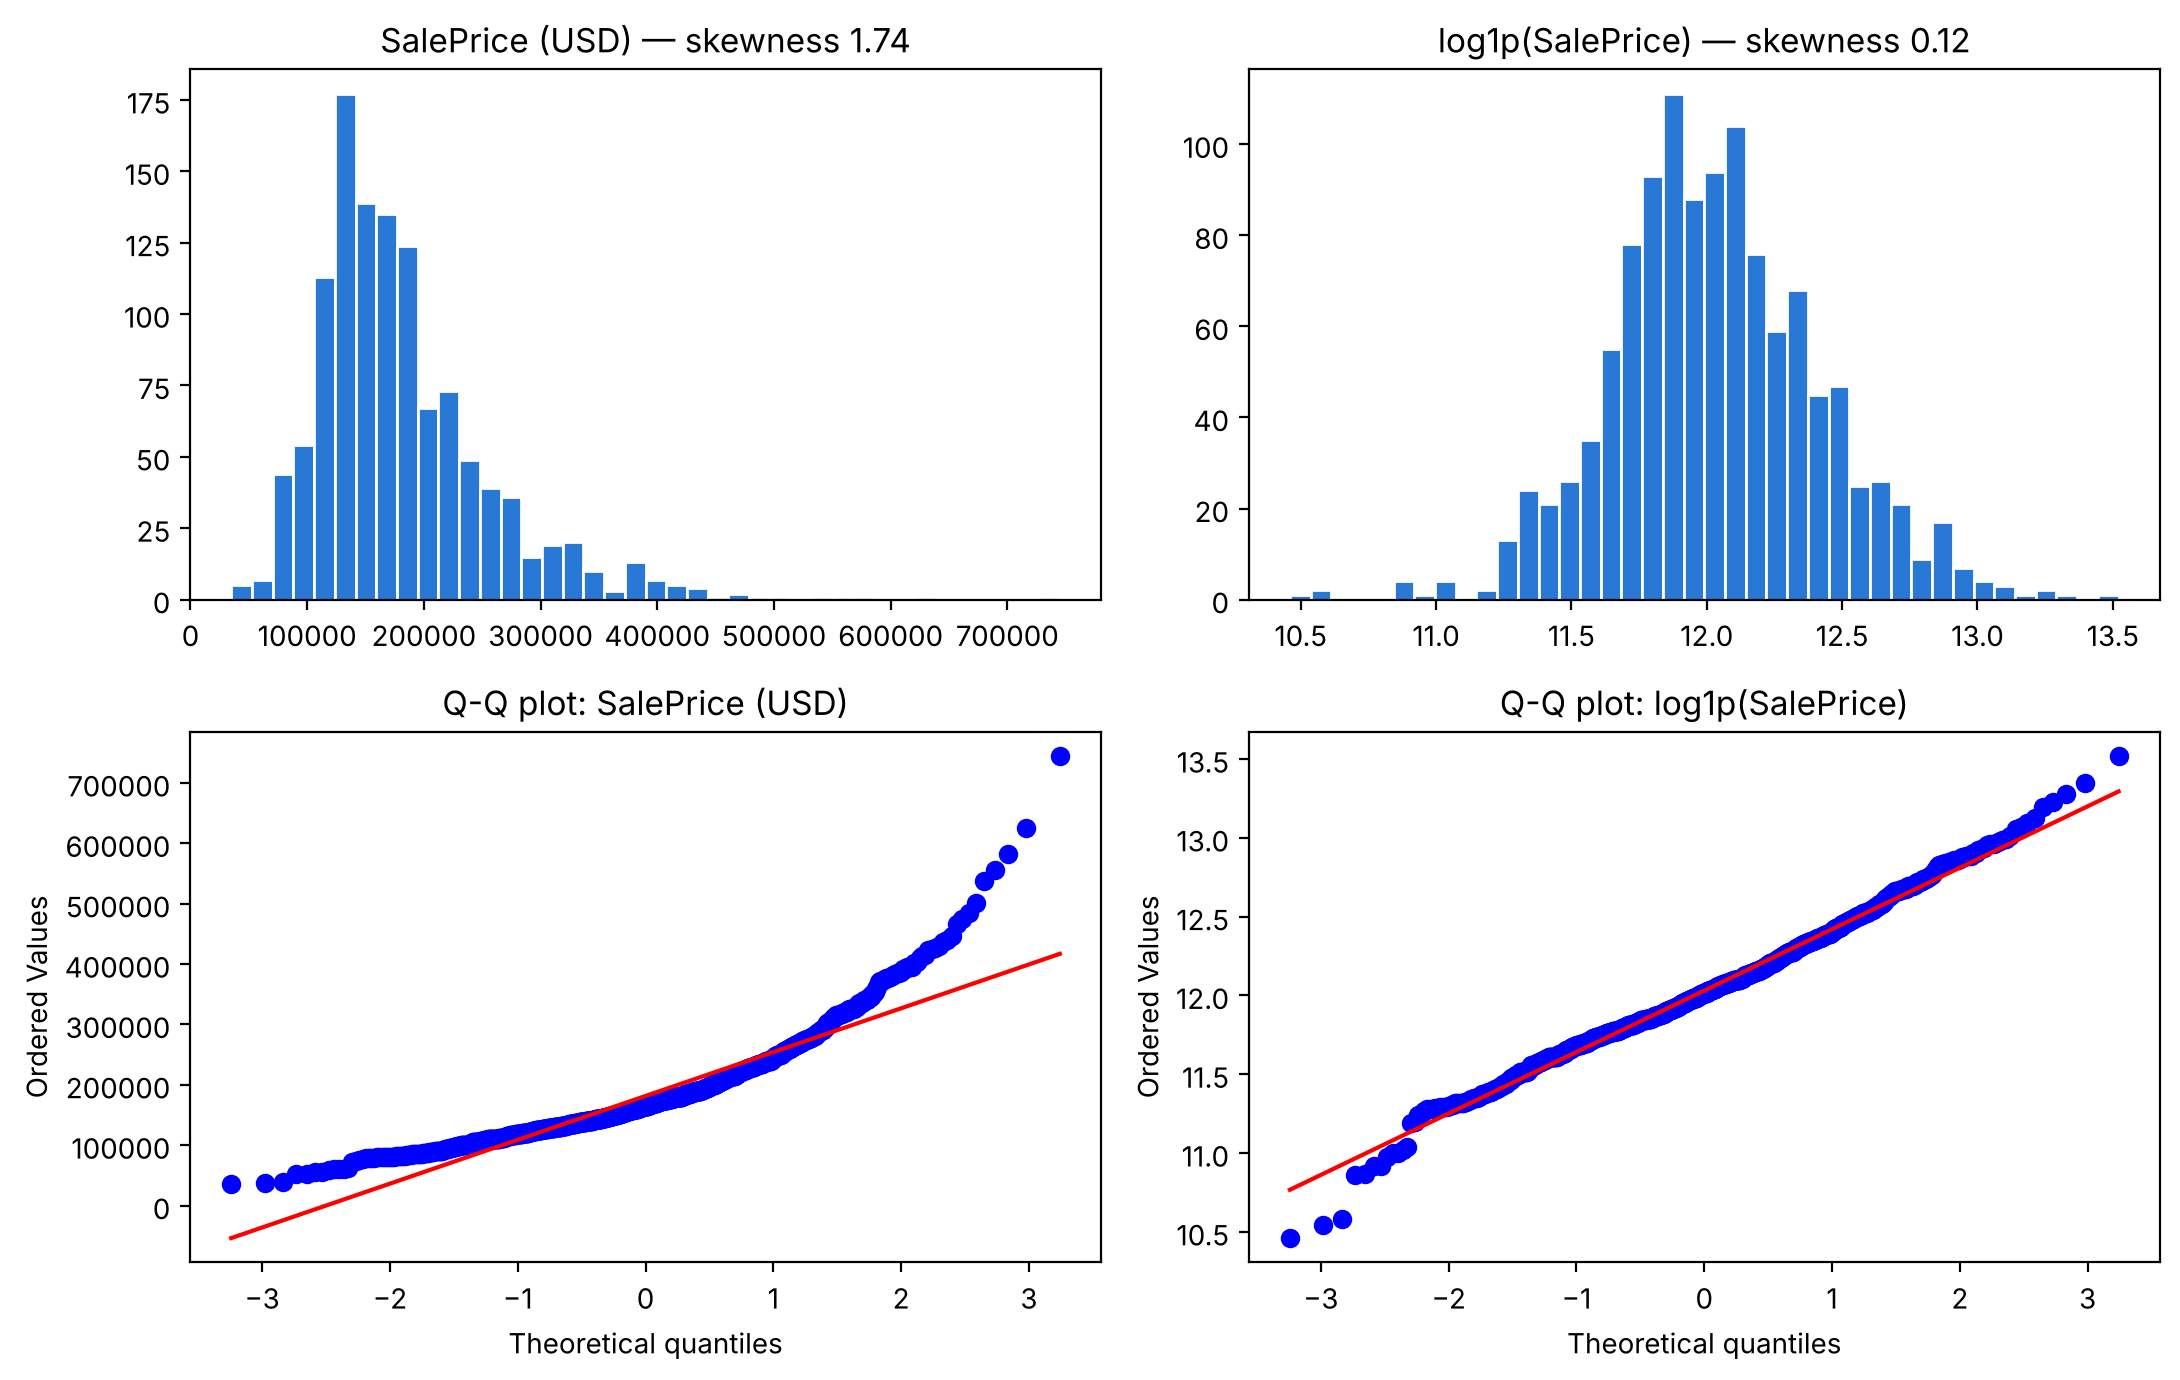

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for j, (nama, s) in enumerate([("SalePrice (USD)", y_train), ("log1p(SalePrice)", ylog)]):
    ax[0, j].hist(s, bins=40, color="#2a78d6", edgecolor="white")
    ax[0, j].set_title(f"{nama} — skewness {s.skew():.2f}")
    stats.probplot(s, dist="norm", plot=ax[1, j]); ax[1, j].set_title(f"Q-Q plot: {nama}")
plt.tight_layout(); plt.show()

**Interpretasi.** Harga asli miring ke kanan (ekor panjang rumah mahal), sedangkan `log1p` membuat distribusi jauh lebih simetris —
alasan model dilatih pada skala log (RMSLE) lalu dikonversi balik dengan `np.expm1`. Angka skewness ada di tabel di atas.
Uji Shapiro tetap menolak normalitas sempurna pada kedua skala (sensitif untuk n besar); yang relevan adalah penurunan skewness, bukan kenormalan eksak.

## 2. Audit Missing Values

Dua kelompok: **NA bermakna** ("fasilitas tidak ada", sesuai `data_description.txt` Ames) dan **missing murni** (data tidak tercatat).
Untuk kolom yang punya "kolom induk" (mis. `GarageArea == 0` ⇒ tidak ada garasi) kita **buktikan dengan data** apakah tiap NA memang bermakna.
Pemetaan semantik kolom bersifat dokumentasi, bukan keputusan dari data uji; hitungan memakai data latih saja.

In [5]:
# kolom -> (kolom induk, nilai induk saat fasilitas tidak ada) ; None = tidak ada induk, mengikuti data_description
bermakna = {
    "Alley": None, "Fence": None, "MiscFeature": None,
    "PoolQC": ("PoolArea", 0), "FireplaceQu": ("Fireplaces", 0),
    "GarageType": ("GarageArea", 0), "GarageFinish": ("GarageArea", 0), "GarageQual": ("GarageArea", 0),
    "GarageCond": ("GarageArea", 0), "GarageYrBlt": ("GarageArea", 0),
    "BsmtQual": ("TotalBsmtSF", 0), "BsmtCond": ("TotalBsmtSF", 0), "BsmtExposure": ("TotalBsmtSF", 0),
    "BsmtFinType1": ("TotalBsmtSF", 0), "BsmtFinType2": ("TotalBsmtSF", 0),
}
murni = ["LotFrontage", "MasVnrType", "MasVnrArea", "Electrical"]
numerik_na = {"GarageYrBlt", "LotFrontage", "MasVnrArea"}

rows = []
for col in list(bermakna) + murni:
    n = int(X_train[col].isna().sum()); n_tot = len(X_train)
    if col in bermakna:
        induk = bermakna[col]
        if induk is None:
            n_ber, n_mur, bukti = n, 0, "tanpa kolom induk; mengikuti data_description"
        else:
            m_ber = int((X_train[col].isna() & (X_train[induk[0]] == induk[1])).sum())
            n_ber, n_mur = m_ber, n - m_ber
            kontra = int((X_train[col].notna() & (X_train[induk[0]] == induk[1])).sum())
            bukti = f"NA & {induk[0]}=={induk[1]}: {m_ber}/{n}; nilai terisi padahal {induk[0]}=={induk[1]}: {kontra}"
        kelompok = "NA bermakna" if n_mur == 0 else "Campuran"
        aksi = "0 (fasilitas tidak ada; tidak dipakai sebagai fitur UI)" if col in numerik_na else "'None'"
        if n_mur > 0: aksi += " ; baris missing murni boleh diisi modus"
    else:
        n_ber, n_mur, kelompok = 0, n, "Missing murni"
        bukti = "tidak ada penjelasan struktural"
        aksi = "median (numerik)" if col in numerik_na else "modus"
    rows.append({"kolom": col, "kelompok": kelompok, "n_na_latih": n, "pct_na_latih": round(100*n/n_tot, 2),
                 "n_bermakna": n_ber, "n_missing_murni": n_mur, "bukti": bukti, "imputasi_disarankan": aksi})
na_map = pd.DataFrame(rows).sort_values(["kelompok", "pct_na_latih"], ascending=[True, False]).reset_index(drop=True)
na_map.to_csv(REPORTS/"na_mapping.csv", index=False)
pd.set_option("display.max_colwidth", 80, "display.width", 200)
display(na_map)

semua_na = X_train.columns[X_train.isna().any()]
print("Kolom ber-NA di data latih yang TIDAK ada di pemetaan:", sorted(set(semua_na) - set(na_map.kolom)))
print("Kolom bernilai 'None' (kategori sah, bukan NA):", {c: int((X_train[c] == 'None').sum()) for c in X_train.columns if (X_train[c] == 'None').any()})

,kolom,kelompok,n_na_latih,pct_na_latih,n_bermakna,n_missing_murni,bukti,imputasi_disarankan
0,LotFrontage,Missing murni,217,18.58,0,217,tidak ada penjelasan struktural,median (numerik)
1,MasVnrType,Missing murni,6,0.51,0,6,tidak ada penjelasan struktural,modus
2,MasVnrArea,Missing murni,6,0.51,0,6,tidak ada penjelasan struktural,median (numerik)
3,Electrical,Missing murni,1,0.09,0,1,tidak ada penjelasan struktural,modus
4,PoolQC,NA bermakna,1162,99.49,1162,0,NA & PoolArea==0: 1162/1162; nilai terisi padahal PoolArea==0: 0,'None'
5,MiscFeature,NA bermakna,1122,96.06,1122,0,tanpa kolom induk; mengikuti data_description,'None'
6,Alley,NA bermakna,1094,93.66,1094,0,tanpa kolom induk; mengikuti data_description,'None'
7,Fence,NA bermakna,935,80.05,935,0,tanpa kolom induk; mengikuti data_description,'None'
8,FireplaceQu,NA bermakna,547,46.83,547,0,NA & Fireplaces==0: 547/547; nilai terisi padahal Fireplaces==0: 0,'None'
9,GarageType,NA bermakna,64,5.48,64,0,NA & GarageArea==0: 64/64; nilai terisi padahal GarageArea==0: 0,'None'


Kolom ber-NA di data latih yang TIDAK ada di pemetaan: []
Kolom bernilai 'None' (kategori sah, bukan NA): {'MasVnrType': 677}


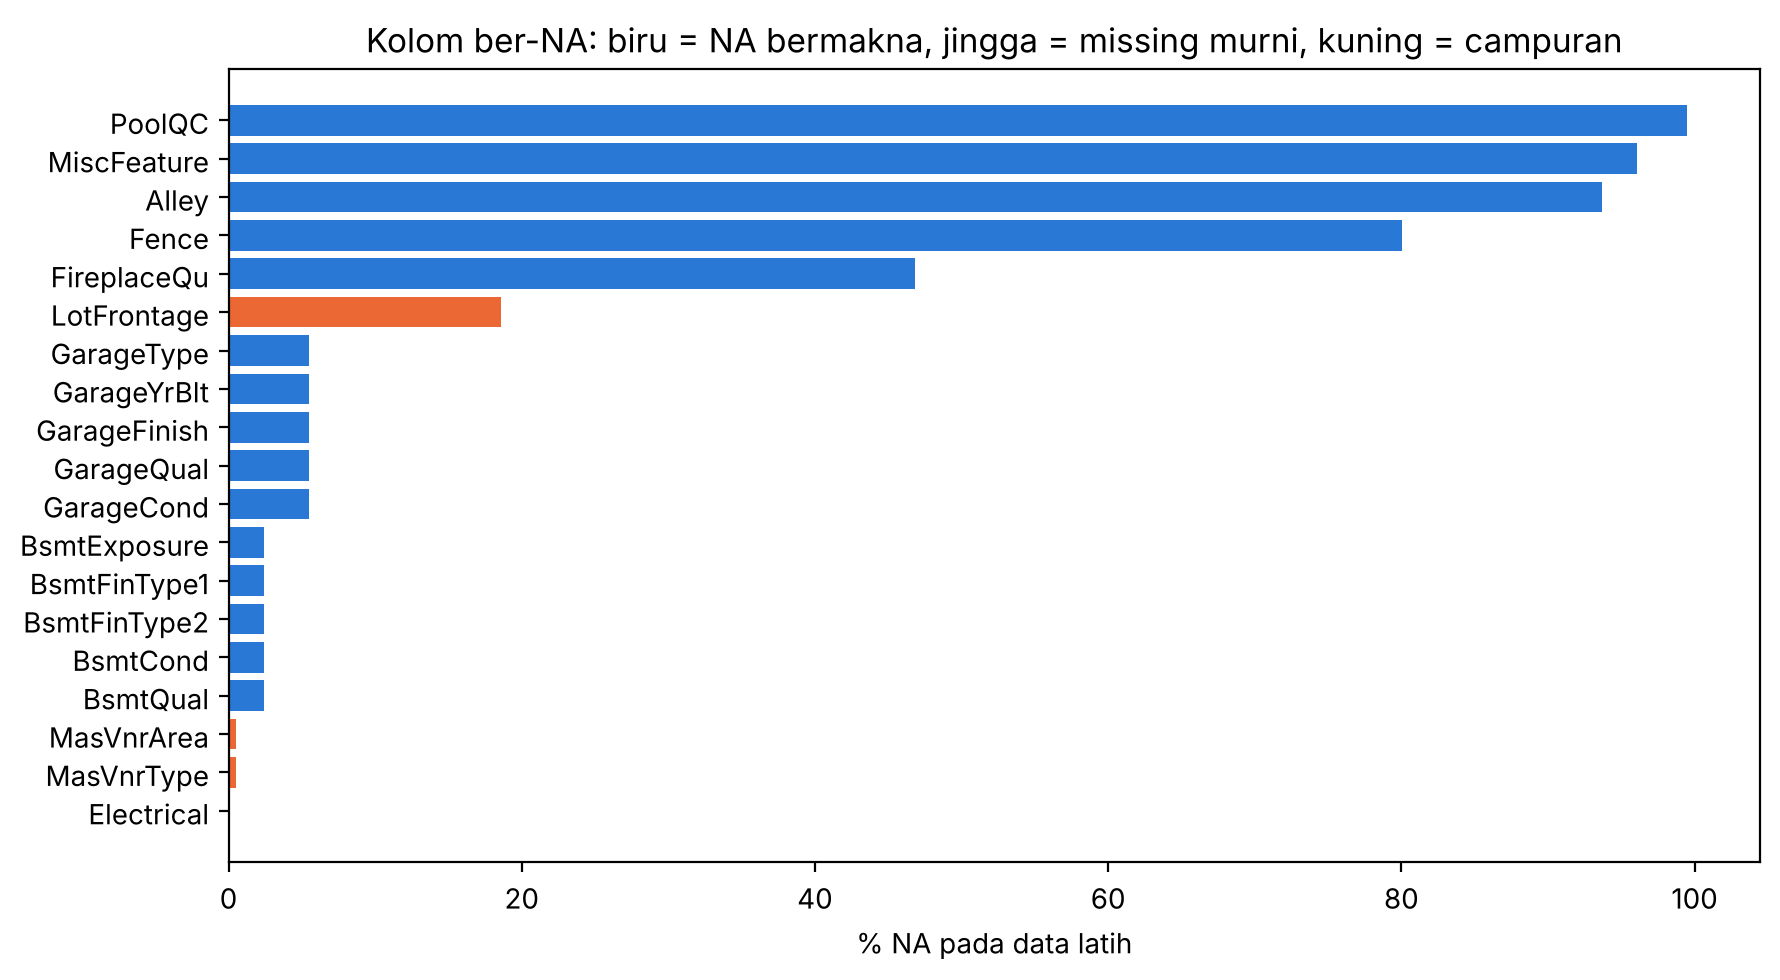

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
d = na_map.sort_values("pct_na_latih")
warna = d.kelompok.map({"NA bermakna": "#2a78d6", "Campuran": "#eda100", "Missing murni": "#eb6834"})
ax.barh(d.kolom, d.pct_na_latih, color=warna)
ax.set_xlabel("% NA pada data latih"); ax.set_title("Kolom ber-NA: biru = NA bermakna, jingga = missing murni, kuning = campuran")
plt.tight_layout(); plt.show()

**Catatan untuk Role 3.** Isi kategorikal bermakna dengan `"None"` (selaras `OrdinalEncoder` urutan `Ex > Gd > TA > Fa > Po > None`). `GarageYrBlt` tidak dipakai langsung
(banyak NA struktural, nyaris duplikat `YearBuilt`). Missing murni diimputasi **di dalam pipeline** dan di-`fit` pada `X_train` saja.

### Audit konsistensi tambahan

In [7]:
cek = {
 "Id duplikat": int(X_train.Id.duplicated().sum()),
 "Baris duplikat (selain Id)": int(X_train.drop(columns="Id").duplicated().sum()),
 "YearBuilt > 2010 (HouseAge negatif)": int((X_train.YearBuilt > REF_YEAR).sum()),
 "YearBuilt > YrSold": int((X_train.YearBuilt > X_train.YrSold).sum()),
 "YearRemodAdd < YearBuilt": int((X_train.YearRemodAdd < X_train.YearBuilt).sum()),
 "GarageYrBlt < YearBuilt": int((X_train.GarageYrBlt < X_train.YearBuilt).sum()),
 "GarageYrBlt > 2010": int((X_train.GarageYrBlt > REF_YEAR).sum()),
 "GrLivArea <= 0 / SalePrice <= 0": int(((X_train.GrLivArea <= 0)).sum() + (y_train <= 0).sum()),
 "TotalBsmtSF == 0 (tanpa basement)": int((X_train.TotalBsmtSF == 0).sum()),
 "HouseAge == 0 (YearBuilt = 2010)": int((X_train.YearBuilt == REF_YEAR).sum()),
}
display(pd.Series(cek, name="jumlah baris").to_frame())

,jumlah baris
Id duplikat,0
Baris duplikat (selain Id),0
YearBuilt > 2010 (HouseAge negatif),0
YearBuilt > YrSold,0
YearRemodAdd < YearBuilt,0
GarageYrBlt < YearBuilt,5
GarageYrBlt > 2010,0
GrLivArea <= 0 / SalePrice <= 0,0
TotalBsmtSF == 0 (tanpa basement),28
HouseAge == 0 (YearBuilt = 2010),1


## 3. Outlier ekstrem

Aturan serah-terima: **`GrLivArea > 4000` dan `SalePrice < 300000`** → hanya **ditandai**. Penghapusan dilakukan Role 4 pada `X_train`/`y_train` saja, **bukan** pada test set.

In [8]:
mask = (train.GrLivArea > 4000) & (train.SalePrice < 300000)
besar = train[train.GrLivArea > 4000]
cols = ["Id", "GrLivArea", "TotalBsmtSF", "OverallQual", "Neighborhood", "SaleCondition", "SalePrice"]
print("Semua rumah dengan GrLivArea > 4000 di data latih:"); display(besar[cols + []].assign(ditandai=mask[besar.index]))
r_before = train[["GrLivArea", "SalePrice"]].corr().iloc[0, 1]
r_after = train.loc[~mask, ["GrLivArea", "SalePrice"]].corr().iloc[0, 1]
print(f"Korelasi Pearson GrLivArea-SalePrice: {r_before:.4f} (semua)  ->  {r_after:.4f} (tanpa outlier ditandai)")
print("Jumlah ditandai:", int(mask.sum()), "dari", len(train))

Semua rumah dengan GrLivArea > 4000 di data latih:


,Id,GrLivArea,TotalBsmtSF,OverallQual,Neighborhood,SaleCondition,SalePrice,ditandai
1182,1183,4476,2396,10,NoRidge,Abnorml,745000,False
523,524,4676,3138,10,Edwards,Partial,184750,True
1298,1299,5642,6110,10,Edwards,Partial,160000,True


Korelasi Pearson GrLivArea-SalePrice: 0.6957 (semua)  ->  0.7285 (tanpa outlier ditandai)
Jumlah ditandai: 2 dari 1168


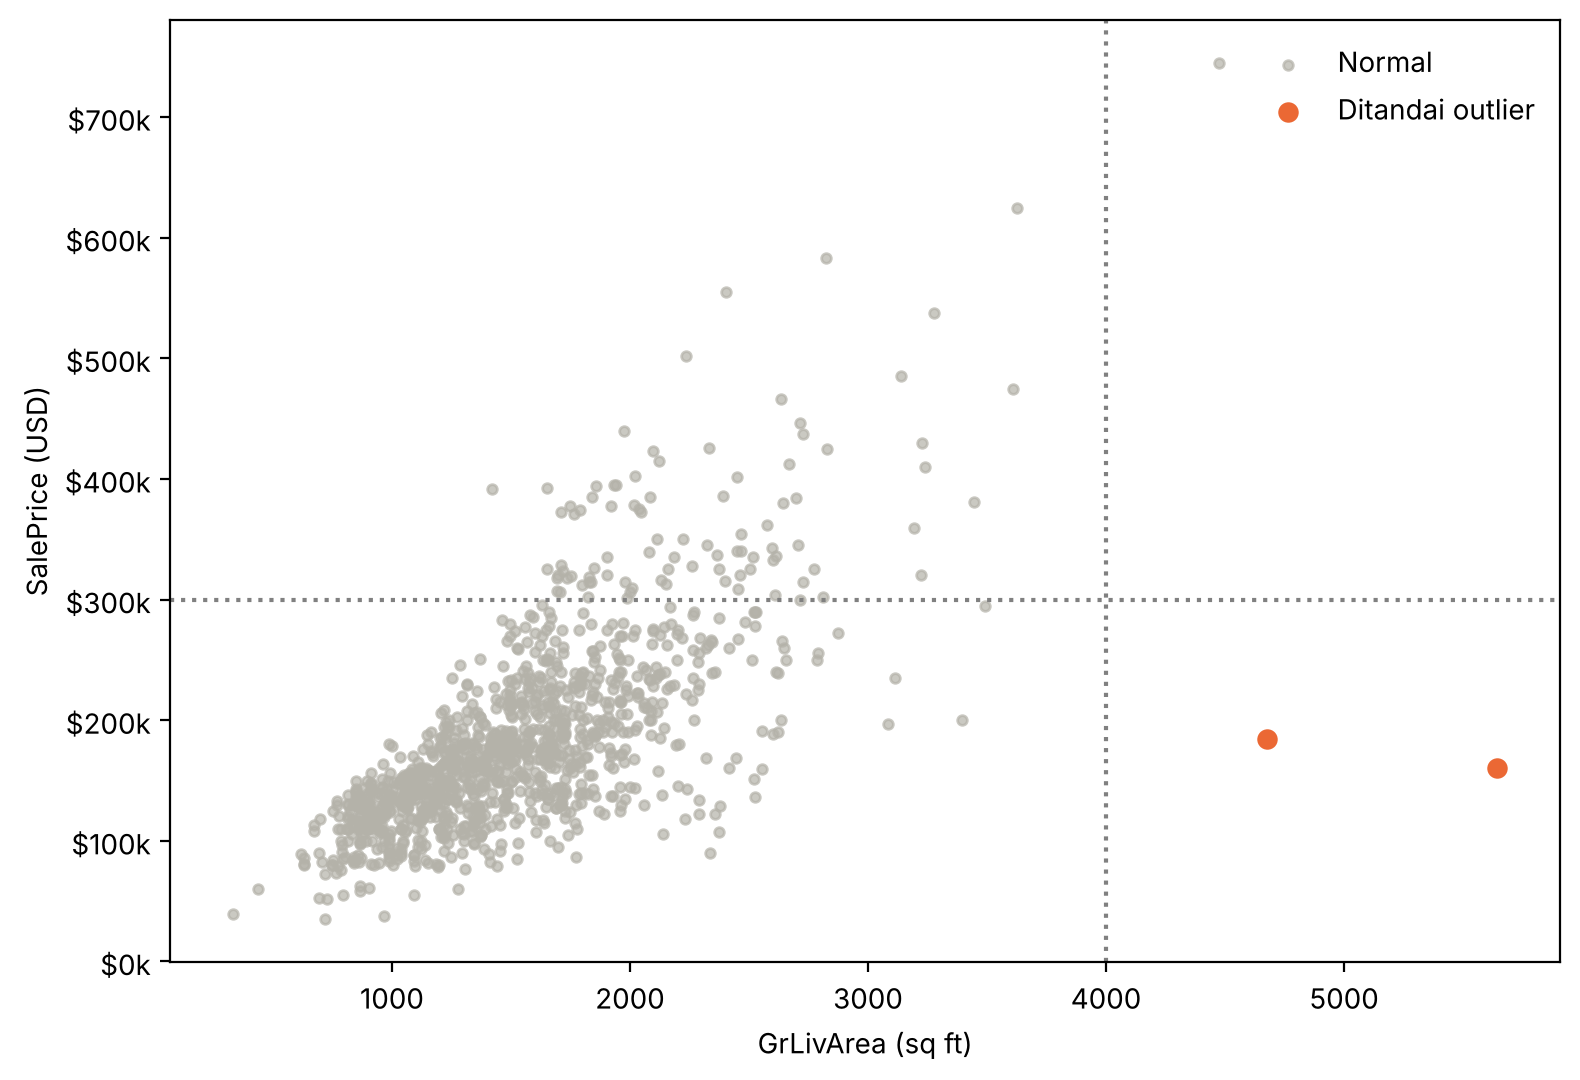

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(train.GrLivArea[~mask], train.SalePrice[~mask], s=12, color="#b4b2a9", alpha=.7, label="Normal")
ax.scatter(train.GrLivArea[mask], train.SalePrice[mask], s=70, color="#eb6834", edgecolor="white", label="Ditandai outlier")
ax.axvline(4000, ls=":", color="gray"); ax.axhline(300000, ls=":", color="gray")
ax.set_xlabel("GrLivArea (sq ft)"); ax.set_ylabel("SalePrice (USD)"); ax.legend(frameon=False)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k")); plt.tight_layout(); plt.show()

In [10]:
# Pemeriksaan tambahan (informasional, TIDAK ikut ditandai): ekstrem univariat pada kolom ukuran besar
info = []
for c in ["LotArea", "LotFrontage", "TotalBsmtSF", "1stFlrSF", "GrLivArea", "MasVnrArea", "BsmtFinSF1"]:
    q1, q3 = train[c].quantile([.25, .75]); batas = q3 + 3*(q3 - q1)
    ekstrem = train.index[train[c] > batas]
    info.append({"kolom": c, "batas_Q3+3IQR": round(batas, 1), "n_ekstrem": len(ekstrem),
                 "irisan_dengan_ditandai": int(mask[ekstrem].sum()), "Id_ekstrem_terbesar": train.loc[train[c].nlargest(3).index, "Id"].tolist()})
display(pd.DataFrame(info))

out = train.loc[mask, ["Id", "GrLivArea", "TotalBsmtSF", "OverallQual", "Neighborhood", "SaleCondition", "SalePrice"]].copy()
out["alasan"] = "GrLivArea>4000 & SalePrice<300000"
out.to_csv(REPORTS/"outliers_flagged.csv", index=False)
display(out)

,kolom,batas_Q3+3IQR,n_ekstrem,irisan_dengan_ditandai,Id_ekstrem_terbesar
0,LotArea,24038.2,28,2,"[314, 336, 250]"
1,LotFrontage,143.0,11,1,"[1299, 935, 1128]"
2,TotalBsmtSF,2809.0,4,2,"[1299, 497, 524]"
3,1stFlrSF,2923.0,3,2,"[1299, 497, 524]"
4,GrLivArea,3730.8,3,2,"[1299, 524, 1183]"
5,MasVnrArea,664.0,17,2,"[1170, 809, 982]"
6,BsmtFinSF1,2884.0,1,1,"[1299, 524, 1183]"


,Id,GrLivArea,TotalBsmtSF,OverallQual,Neighborhood,SaleCondition,SalePrice,alasan
523,524,4676,3138,10,Edwards,Partial,184750,GrLivArea>4000 & SalePrice<300000
1298,1299,5642,6110,10,Edwards,Partial,160000,GrLivArea>4000 & SalePrice<300000


**Interpretasi.** Rumah ber-`GrLivArea` sangat besar yang harganya wajar (tinggi) **tidak** ditandai; hanya yang harganya tidak sebanding dengan ukurannya.
Kolom `SaleCondition` pada tabel membantu menjelaskan penyebab (bukan fitur model). **Handover Role 4:** hapus baris dengan `Id` di `reports/outliers_flagged.csv`
dari `X_train`/`y_train`; jangan menyentuh test set.

## 4. Ranking kandidat fitur (data latih saja)

Tiga ukuran, digabung dengan **rata-rata peringkat**:
1. **Asosiasi dengan `log1p(SalePrice)`** — |Spearman| untuk numerik/ordinal kualitas; rasio korelasi η untuk nominal.
2. **Random Forest impurity importance** (dijumlahkan per kolom asal agar one-hot tidak memecah skor).
3. **Permutation importance** pada validasi internal (20% dari data latih) agar tidak bias ke kolom berkardinalitas tinggi.

Kolom transaksi (`SaleType`, `SaleCondition`, `MoSold`, `YrSold`) tidak diranking (dikecualikan oleh kriteria PRD #4), hanya dilaporkan asosiasinya.

In [11]:
TRANSAKSI = ["SaleType", "SaleCondition", "MoSold", "YrSold"]
KUALITAS = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
QMAP = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "None": 0}

W = X_train.drop(columns="Id").copy()
W["MSSubClass"] = W["MSSubClass"].astype(str)                       # kode kategori, bukan angka
for c in bermakna:                                                  # NA bermakna -> "None" (kategorikal)
    if c not in numerik_na: W[c] = W[c].fillna("None")
for c in KUALITAS: W[c] = W[c].map(QMAP)                            # ordinal berurutan
nom_cols = [c for c in W.columns if not pd.api.types.is_numeric_dtype(W[c])]
num_cols = [c for c in W.columns if c not in nom_cols]
tipe = {**{c: "ordinal_kualitas" for c in KUALITAS}, **{c: "nominal" for c in nom_cols},
        **{c: ("numerik_int" if pd.api.types.is_integer_dtype(X_train[c]) else "numerik_float") for c in num_cols if c not in KUALITAS}}

# --- (1) asosiasi dengan target ---
asosiasi, pearson = {}, {}
for c in num_cols:
    asosiasi[c] = abs(W[c].corr(ylog, method="spearman")); pearson[c] = W[c].corr(ylog)
sst = ((ylog - ylog.mean())**2).sum()
for c in nom_cols:
    g = ylog.groupby(W[c]); ssb = (g.count() * (g.mean() - ylog.mean())**2).sum()
    asosiasi[c] = float(np.sqrt(ssb/sst)); pearson[c] = np.nan

# --- (2)(3) Random Forest ---
fitur = [c for c in W.columns if c not in TRANSAKSI]
num_f = [c for c in fitur if c in num_cols]; nom_f = [c for c in fitur if c in nom_cols]
def bangun_rf():
    pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), num_f),
                             ("nom", OneHotEncoder(handle_unknown="ignore"), nom_f)])
    return Pipeline([("pre", pre), ("rf", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.33,
                                                               random_state=RANDOM_STATE, n_jobs=-1))])
rf = bangun_rf().fit(W[fitur], ylog)
nama_out = rf[:-1].get_feature_names_out(); imp = rf[-1].feature_importances_
rf_imp = {}
for c in fitur:
    pref = f"num__{c}" if c in num_f else f"nom__{c}_"
    rf_imp[c] = float(sum(v for n, v in zip(nama_out, imp) if (n == pref if c in num_f else n.startswith(pref))))
print("Jumlah impurity importance (harus ~1):", round(sum(rf_imp.values()), 4))

W_fit, W_val, y_fit, y_val = train_test_split(W[fitur], ylog, test_size=0.2, random_state=RANDOM_STATE)
rf_val = bangun_rf().fit(W_fit, y_fit)
print(f"R2 validasi internal RF (skala log, hanya sanity check): {rf_val.score(W_val, y_val):.3f}")
pi = permutation_importance(rf_val, W_val, y_val, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm = dict(zip(fitur, pi.importances_mean))

rank_df = pd.DataFrame({"asosiasi_target": pd.Series(asosiasi)[fitur], "rf_impurity": pd.Series(rf_imp), "rf_permutation": pd.Series(perm)})
rank_df["skor_peringkat"] = rank_df.rank(ascending=False).mean(axis=1)
rank_df["ranking_importance"] = rank_df.skor_peringkat.rank(method="first").astype(int)
rank_df = rank_df.sort_values("ranking_importance")
display(rank_df.head(15).round(4))

Jumlah impurity importance (harus ~1): 1.0


R2 validasi internal RF (skala log, hanya sanity check): 0.882


,asosiasi_target,rf_impurity,rf_permutation,skor_peringkat,ranking_importance
OverallQual,0.8010,0.2282,0.1060,1.3333,1
GrLivArea,0.7234,0.1541,0.1130,2.0000,2
YearBuilt,0.6432,0.0573,0.0181,5.0000,3
GarageCars,0.6868,0.0402,0.0150,5.3333,4
ExterQual,0.6648,0.0828,0.0088,6.6667,5
BsmtQual,0.6743,0.0274,0.0156,6.6667,6
TotalBsmtSF,0.5950,0.0388,0.0170,7.6667,7
GarageArea,0.6387,0.0332,0.0104,8.3333,8
KitchenQual,0.6648,0.0405,0.0061,9.0000,9
1stFlrSF,0.5663,0.0321,0.0128,10.6667,10


In [12]:
# sensitivitas: apakah ranking berubah jika outlier ikut disingkirkan dari data latih?
idx_ok = train.index[~mask]
rf2 = bangun_rf().fit(W.loc[idx_ok, fitur], ylog[idx_ok])
imp2 = rf2[-1].feature_importances_; nama2 = rf2[:-1].get_feature_names_out()
rf_imp2 = {c: float(sum(v for n, v in zip(nama2, imp2) if (n == f"num__{c}" if c in num_f else n.startswith(f"nom__{c}_")))) for c in fitur}
rho, _ = stats.spearmanr(pd.Series(rf_imp)[fitur], pd.Series(rf_imp2)[fitur])
top_a = set(pd.Series(rf_imp).nlargest(15).index); top_b = set(pd.Series(rf_imp2).nlargest(15).index)
print(f"Korelasi peringkat RF impurity dengan/tanpa outlier: {rho:.3f} | irisan top-15: {len(top_a & top_b)}/15")

Korelasi peringkat RF impurity dengan/tanpa outlier: 0.992 | irisan top-15: 14/15


In [13]:
# --- korelasi dengan fitur lain (numerik + ordinal, Spearman berpasangan) ---
cm = W[num_cols].corr(method="spearman").abs()
cm = cm.mask(np.eye(len(cm), dtype=bool), 0.0)
mitra = cm.idxmax(); mitra_val = cm.max()

top15 = rank_df.head(15).index.tolist()
pasangan = [(a, b, round(W[a].corr(W[b], method="spearman"), 3)) for i, a in enumerate(top15) for b in top15[i+1:]
            if a in num_cols and b in num_cols and abs(W[a].corr(W[b], method="spearman")) >= 0.6]
print("Pasangan redundan di antara 15 fitur teratas (|Spearman| >= 0.6) — pertimbangan Role 1 (kriteria #3):")
display(pd.DataFrame(pasangan, columns=["fitur_A", "fitur_B", "spearman"]).sort_values("spearman", key=abs, ascending=False))

Pasangan redundan di antara 15 fitur teratas (|Spearman| >= 0.6) — pertimbangan Role 1 (kriteria #3):


,fitur_A,fitur_B,spearman
8,YearBuilt,GarageYrBlt,0.887
9,GarageCars,GarageArea,0.843
15,TotalBsmtSF,1stFlrSF,0.824
7,YearBuilt,BsmtQual,0.766
12,ExterQual,KitchenQual,0.723
14,BsmtQual,GarageYrBlt,0.710
1,OverallQual,ExterQual,0.702
6,YearBuilt,ExterQual,0.666
2,OverallQual,BsmtQual,0.665
3,OverallQual,KitchenQual,0.663


### 4b. Tabel `reports/feature_candidates.csv`

In [14]:
rows = []
for c in X_train.columns.drop("Id"):
    s = X_train[c]; tp = tipe.get(c, "nominal")
    is_num = tp.startswith("numerik")
    cat = "" if is_num else "|".join(sorted(s.dropna().astype(str).unique(), key=str))
    catatan = []
    if c in TRANSAKSI: catatan.append("transaksi: dikecualikan (kriteria #4)")
    if c in bermakna: catatan.append("NA bermakna -> 'None'/0")
    if c in murni: catatan.append("missing murni")
    if c in mitra.index and mitra_val[c] >= 0.7: catatan.append(f"redundan dengan {mitra[c]}")
    rows.append({
        "nama": c, "tipe": tp,
        "min": s.min() if is_num else np.nan, "max": s.max() if is_num else np.nan,
        "p01": s.quantile(.01) if is_num else np.nan, "p99": s.quantile(.99) if is_num else np.nan,
        "kategori": cat, "n_kategori": 0 if is_num else s.nunique(),
        "pct_missing": round(100*s.isna().mean(), 2),
        "ranking_importance": rank_df.ranking_importance.get(c, np.nan),
        "asosiasi_target": round(asosiasi[c], 4) if c in asosiasi else np.nan,
        "rf_impurity": round(rf_imp[c], 4) if c in rf_imp else np.nan,
        "rf_permutation": round(perm[c], 4) if c in perm else np.nan,
        "korelasi_tertinggi_dengan": mitra.get(c, np.nan), "korelasi_tertinggi_nilai": round(mitra_val.get(c, np.nan), 3),
        "catatan": "; ".join(catatan)})
cand = pd.DataFrame(rows).sort_values("ranking_importance", na_position="last").reset_index(drop=True)
cand["ranking_importance"] = cand["ranking_importance"].astype("Int64")
cand.to_csv(REPORTS/"feature_candidates.csv", index=False)
print("Baris:", len(cand), "| kolom:", list(cand.columns))
display(cand.head(15)[["ranking_importance", "nama", "tipe", "min", "max", "kategori", "pct_missing", "asosiasi_target", "korelasi_tertinggi_dengan", "korelasi_tertinggi_nilai", "catatan"]])

Baris: 79 | kolom: ['nama', 'tipe', 'min', 'max', 'p01', 'p99', 'kategori', 'n_kategori', 'pct_missing', 'ranking_importance', 'asosiasi_target', 'rf_impurity', 'rf_permutation', 'korelasi_tertinggi_dengan', 'korelasi_tertinggi_nilai', 'catatan']


,ranking_importance,nama,tipe,min,max,kategori,pct_missing,asosiasi_target,korelasi_tertinggi_dengan,korelasi_tertinggi_nilai,catatan
0,1,OverallQual,numerik_int,1.0,10.0,,0.00,0.8010,ExterQual,0.702,redundan dengan ExterQual
1,2,GrLivArea,numerik_int,334.0,5642.0,,0.00,0.7234,TotRmsAbvGrd,0.824,redundan dengan TotRmsAbvGrd
2,3,YearBuilt,numerik_int,1872.0,2010.0,,0.00,0.6432,GarageYrBlt,0.887,redundan dengan GarageYrBlt
3,4,GarageCars,numerik_int,0.0,4.0,,0.00,0.6868,GarageArea,0.843,redundan dengan GarageArea
4,5,ExterQual,ordinal_kualitas,NaN,NaN,Ex|Fa|Gd|TA,0.00,0.6648,KitchenQual,0.723,redundan dengan KitchenQual
5,6,BsmtQual,ordinal_kualitas,NaN,NaN,Ex|Fa|Gd|TA,2.40,0.6743,YearBuilt,0.766,NA bermakna -> 'None'/0; redundan dengan YearBuilt
6,7,TotalBsmtSF,numerik_int,0.0,6110.0,,0.00,0.5950,1stFlrSF,0.824,redundan dengan 1stFlrSF
7,8,GarageArea,numerik_int,0.0,1418.0,,0.00,0.6387,GarageCars,0.843,redundan dengan GarageCars
8,9,KitchenQual,ordinal_kualitas,NaN,NaN,Ex|Fa|Gd|TA,0.00,0.6648,ExterQual,0.723,redundan dengan ExterQual
9,10,1stFlrSF,numerik_int,334.0,4692.0,,0.00,0.5663,TotalBsmtSF,0.824,redundan dengan TotalBsmtSF


## 5. Ekspor grafik wawasan (300 DPI → `reports/figures/`)
Warna: biru = data utama, abu-abu = konteks, jingga = peringatan/outlier. Satu hue berurutan (terang→gelap) untuk kualitas.

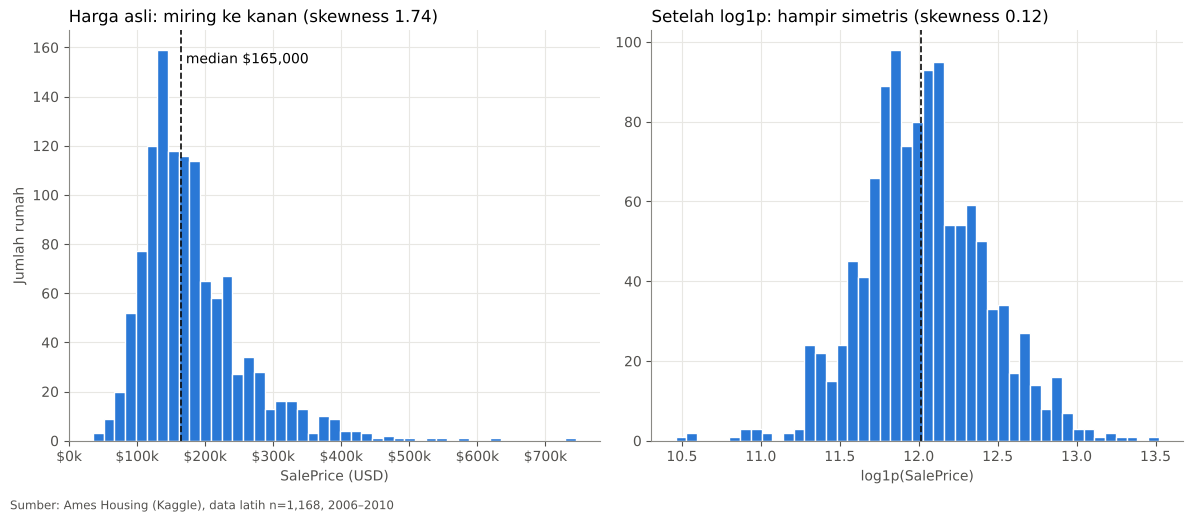

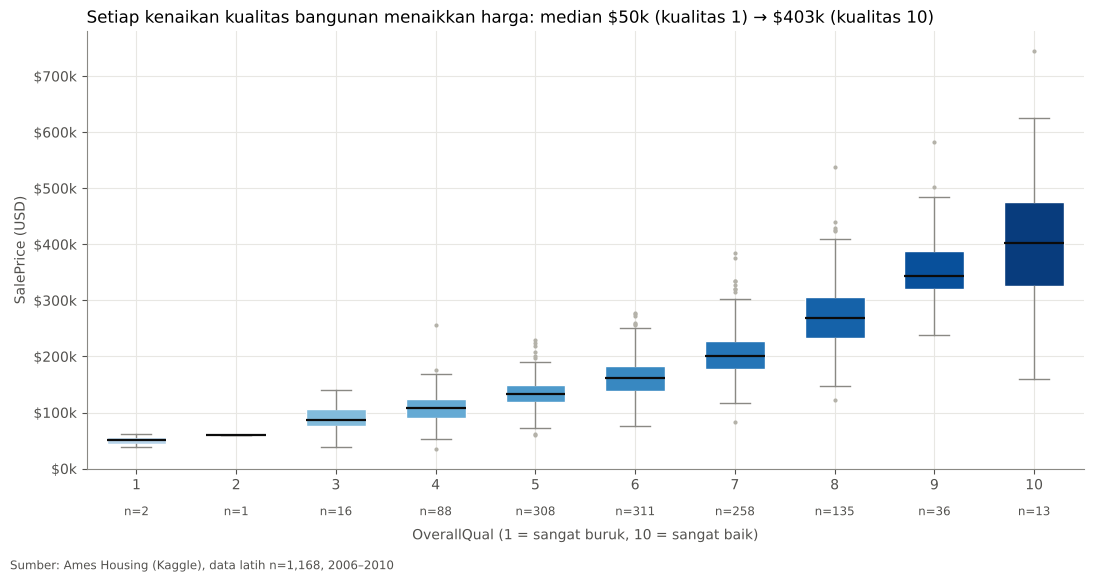

OverallQual       1        2        3         4         5         6         7         8         9         10
median       50150.0  60000.0  86250.0  108250.0  133850.0  161750.0  200000.0  268000.0  343822.0  402861.0
count            2.0      1.0     16.0      88.0     308.0     311.0     258.0     135.0      36.0      13.0


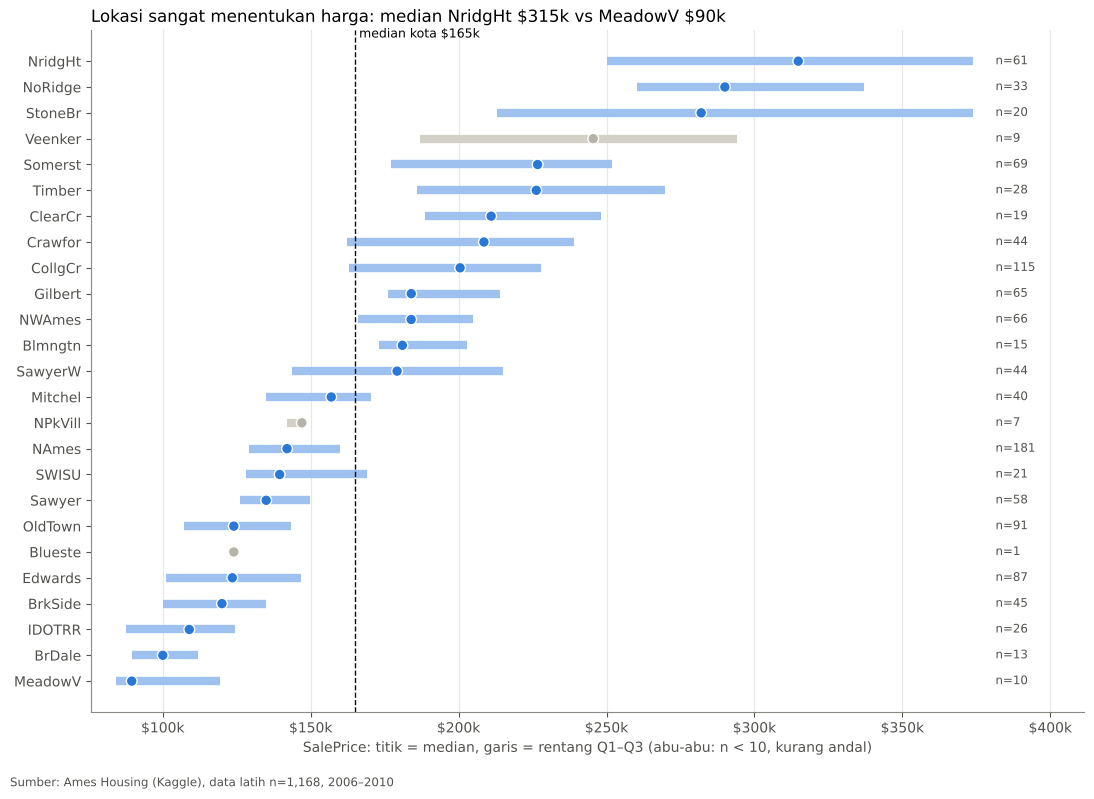

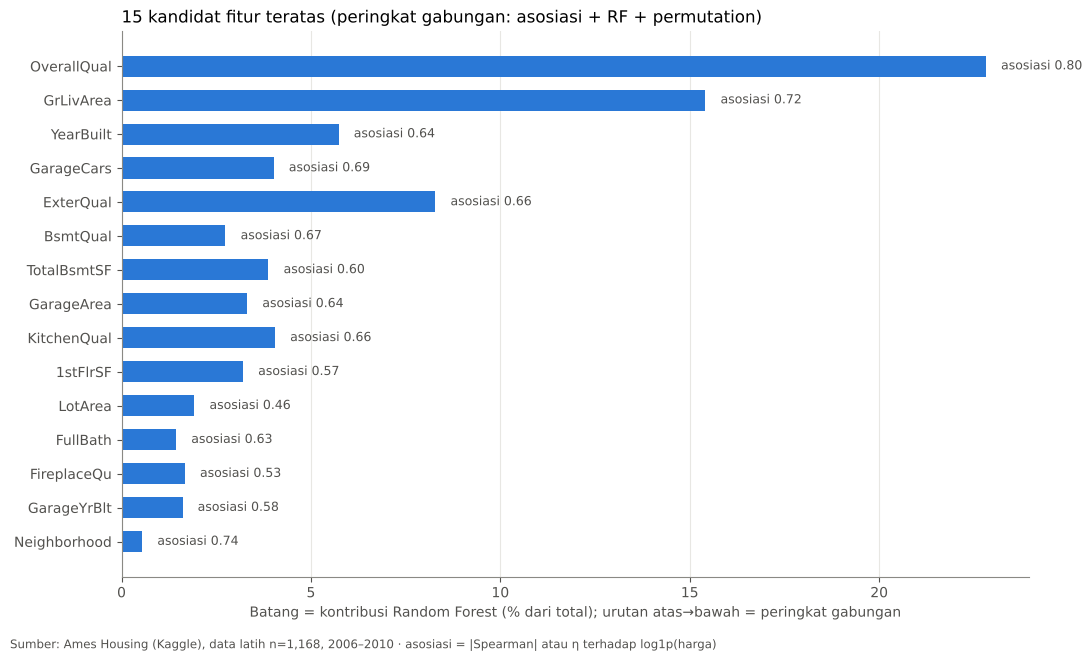

In [15]:
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": .8, "axes.axisbelow": True, "figure.dpi": 100})
BLUE, GRAY, INK = "#2a78d6", "#b4b2a9", "#0b0b0b"
usd_k = FuncFormatter(lambda v, _: f"${v/1000:,.0f}k")
SUMBER = f"Sumber: Ames Housing (Kaggle), data latih n={len(train):,}, 2006–2010"

# ---- Gambar 1: distribusi harga ----
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
ax[0].hist(y_train, bins=45, color=BLUE, edgecolor="white")
ax[0].axvline(y_train.median(), color=INK, ls="--", lw=1.2)
ax[0].text(y_train.median()*1.04, ax[0].get_ylim()[1]*.92, f"median \${y_train.median():,.0f}", fontsize=10)
ax[0].set_title(f"Harga asli: miring ke kanan (skewness {skew_before:.2f})", loc="left", fontsize=12)
ax[0].xaxis.set_major_formatter(usd_k); ax[0].set_xlabel("SalePrice (USD)"); ax[0].set_ylabel("Jumlah rumah")
ax[1].hist(ylog, bins=45, color=BLUE, edgecolor="white")
ax[1].axvline(ylog.median(), color=INK, ls="--", lw=1.2)
ax[1].set_title(f"Setelah log1p: hampir simetris (skewness {skew_after:.2f})", loc="left", fontsize=12)
ax[1].set_xlabel("log1p(SalePrice)"); ax[1].set_ylabel("")
fig.text(0.01, 0.01, SUMBER, fontsize=8.5, color="#52514e"); plt.tight_layout(rect=(0, .03, 1, 1))
fig.savefig(FIGS/"01_distribusi_harga.png", dpi=300, facecolor="white"); plt.show()

# ---- Gambar 2: kualitas bangunan vs harga ----
q = train.groupby("OverallQual").SalePrice.agg(["median", "count"])
niveau = sorted(train.OverallQual.unique())
data = [train.loc[train.OverallQual == k, "SalePrice"] for k in niveau]
ramp = plt.cm.Blues(np.linspace(.3, .95, len(niveau)))
fig, ax = plt.subplots(figsize=(11, 5.8))
bp = ax.boxplot(data, positions=niveau, widths=.6, patch_artist=True, showfliers=True,
                medianprops=dict(color=INK, lw=1.6), flierprops=dict(marker="o", ms=3, markerfacecolor=GRAY, markeredgecolor="none"),
                whiskerprops=dict(color="#8a8984"), capprops=dict(color="#8a8984"))
for patch, col in zip(bp["boxes"], ramp): patch.set_facecolor(col); patch.set_edgecolor("white")
for k in niveau: ax.text(k, -0.085, f"n={int(q.loc[k,'count'])}", ha="center", va="top", fontsize=8.5, color="#52514e", transform=ax.get_xaxis_transform())
lo, hi = niveau[0], niveau[-1]
ax.set_title(f"Setiap kenaikan kualitas bangunan menaikkan harga: median \${q.loc[lo,'median']/1000:,.0f}k (kualitas {lo}) → \${q.loc[hi,'median']/1000:,.0f}k (kualitas {hi})", loc="left", fontsize=12)
ax.set_xlabel("OverallQual (1 = sangat buruk, 10 = sangat baik)", labelpad=26); ax.set_ylabel("SalePrice (USD)"); ax.yaxis.set_major_formatter(usd_k)
fig.text(0.01, 0.01, SUMBER, fontsize=8.5, color="#52514e"); plt.tight_layout(rect=(0, .03, 1, 1))
fig.savefig(FIGS/"02_kualitas_vs_harga.png", dpi=300, facecolor="white"); plt.show()
print(q.assign(median=q["median"].round(0)).T)

# ---- Gambar 3: harga per Neighborhood ----
g = train.groupby("Neighborhood").SalePrice.agg(median="median", q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75), n="count").sort_values("median")
kecil = g.n < 10
fig, ax = plt.subplots(figsize=(11, 8))
yy = np.arange(len(g))
ax.hlines(yy, g.q1, g.q3, color=np.where(kecil, "#d3d1c7", "#9ec1ef"), lw=6)
ax.scatter(g["median"], yy, s=60, zorder=3, color=np.where(kecil, GRAY, BLUE), edgecolor="white")
ax.axvline(y_train.median(), color=INK, ls="--", lw=1)
ax.text(y_train.median(), len(g)-.2, f" median kota \${y_train.median()/1000:,.0f}k", fontsize=9, va="bottom")
for i, (nm, r) in enumerate(g.iterrows()): ax.text(g.q3.max()*1.02, i, f"n={int(r.n)}", va="center", fontsize=8.5, color="#52514e")
ax.set_yticks(yy); ax.set_yticklabels(g.index); ax.xaxis.set_major_formatter(usd_k)
ax.set_xlim(g.q1.min()*.9, g.q3.max()*1.1)
ax.set_xlabel("SalePrice: titik = median, garis = rentang Q1–Q3 (abu-abu: n < 10, kurang andal)")
ax.set_title(f"Lokasi sangat menentukan harga: median {g.index[-1]} \${g['median'].iloc[-1]/1000:,.0f}k vs {g.index[0]} \${g['median'].iloc[0]/1000:,.0f}k", loc="left", fontsize=12)
ax.grid(axis="y", visible=False)
fig.text(0.01, 0.01, SUMBER, fontsize=8.5, color="#52514e"); plt.tight_layout(rect=(0, .03, 1, 1))
fig.savefig(FIGS/"03_harga_per_neighborhood.png", dpi=300, facecolor="white"); plt.show()

# ---- Gambar 4: 15 fitur teratas ----
t = rank_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6.6))
ax.barh(t.index, t.rf_impurity*100, color=BLUE, height=.62)
for i, (nm, r) in enumerate(t.iterrows()):
    ax.text(r.rf_impurity*100 + .4, i, f"asosiasi {r.asosiasi_target:.2f}", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("Batang = kontribusi Random Forest (% dari total); urutan atas→bawah = peringkat gabungan"); ax.grid(axis="y", visible=False)
ax.set_title("15 kandidat fitur teratas (peringkat gabungan: asosiasi + RF + permutation)", loc="left", fontsize=12)
fig.text(0.01, 0.01, SUMBER + " · asosiasi = |Spearman| atau η terhadap log1p(harga)", fontsize=8.5, color="#52514e"); plt.tight_layout(rect=(0, .03, 1, 1))
fig.savefig(FIGS/"04_top15_fitur.png", dpi=300, facecolor="white"); plt.show()

In [16]:
from PIL import Image
for p in sorted(FIGS.glob("*.png")):
    im = Image.open(p); print(p.name, im.size, "dpi:", tuple(round(d) for d in im.info.get("dpi", (0, 0))))

01_distribusi_harga.png (3600, 1560) dpi: (300, 300)
02_kualitas_vs_harga.png (3300, 1740) dpi: (300, 300)
03_harga_per_neighborhood.png (3300, 2400) dpi: (300, 300)
04_top15_fitur.png (3300, 1980) dpi: (300, 300)


## 6. Ringkasan serah-terima
| Ke | Artefak | Catatan |
|---|---|---|
| **Role 1** | `reports/feature_candidates.csv` (diurutkan menurut peringkat) | Lihat tabel pasangan redundan (kriteria #3) dan kolom `catatan`; transaksi sudah dikecualikan dari ranking |
| **Role 3** | `reports/na_mapping.csv` | Aksi imputasi per kolom; baca CSV dengan `keep_default_na=False, na_values=["NA"]` |
| **Role 4** | `reports/outliers_flagged.csv` | Hapus hanya dari `X_train`/`y_train`; split: `train_test_split(X, y, test_size=0.2, random_state=42)` pada urutan baris asli |
| **Slide** | `reports/figures/01–04_*.png` | 300 DPI |

In [17]:
print("Ringkasan angka (semua dari sel di atas):")
print(f"- skewness SalePrice {skew_before:.3f} -> log1p {skew_after:.3f}")
print(f"- kolom ber-NA bermakna: {(na_map.kelompok=='NA bermakna').sum()}, campuran: {(na_map.kelompok=='Campuran').sum()}, missing murni: {(na_map.kelompok=='Missing murni').sum()}")
print(f"- outlier ditandai: {int(mask.sum())} (Id {out.Id.tolist()})")
print("- top-15:", ", ".join(rank_df.head(15).index))

Ringkasan angka (semua dari sel di atas):
- skewness SalePrice 1.743 -> log1p 0.125
- kolom ber-NA bermakna: 15, campuran: 0, missing murni: 4
- outlier ditandai: 2 (Id [524, 1299])
- top-15: OverallQual, GrLivArea, YearBuilt, GarageCars, ExterQual, BsmtQual, TotalBsmtSF, GarageArea, KitchenQual, 1stFlrSF, LotArea, FullBath, FireplaceQu, GarageYrBlt, Neighborhood
